## 6. 보간법
주어진 데이터를 빠짐없이 정확히 통과하는 곡선 / 함수를 만드는 방법

interpolation(데이터 사이에 있는 값) vs extrapolation(데이터를 바탕으로 그밖에 있는 값 추정)

scipy.interpolate 모듈 : https://docs.scipy.org/doc/scipy/tutorial/interpolate.html

---

In [1]:
import numpy as np
# import matplotlib
# matplotlib.use("Agg")  # 테스트용: 화면 없이 그림만 생성 (원본 스크립트에는 없던 줄, 실행 환경 때문에 추가)
import matplotlib.pyplot as plt

#### 6.4. 스플라인 보간법

In [ ]:
class SplineInterpolation:
    """스플라인 보간법 7종 [Lesson Code]

    (1) random points 단계를 __init__으로 옮겨 공통 데이터를 쓰도록 한 것과, 
    각 스크립트의 전역 변수(x, y, n 등)를 self.x, self.y, self.n 등으로 바꿈
    """

    def __init__(self, x, y):
        """
        Args:
            x: 증가하는 순서의 데이터 포인트 x좌표 (각 원본 스크립트의 (1) 단계에서 생성하던 값)
            y: 각 x에 대응하는 y좌표
        """
        self.x = np.asarray(x, dtype=float)
        self.y = np.asarray(y, dtype=float)
        self.n = len(self.x)

    @classmethod
    def random_points(cls, n=8, seed=None):
        """각 원본 스크립트의 (1) random points 단계와 동일한 방식으로 데이터를 생성"""
        # (1) random points (distinct, increasing x)
        rng = np.random.default_rng(seed)
        x = np.cumsum(0.5 + rng.random(n))
        y = rng.random(n)
        return cls(x, y)

    # =====================================================================
    # linear_spline_lagrange.py 
    # =====================================================================
    def linear_spline_lagrange(self):
        # Linear spline based on Lagrange form polynomials: no linear system.
        # Each piece is the line through (x_i,y_i) and (x_{i+1},y_{i+1}):
        #   f_i(x) = (x-x_{i+1})/(x_i-x_{i+1})*y_i + (x-x_i)/(x_{i+1}-x_i)*y_{i+1}
        #   on [x_i, x_{i+1}],  i = 1,...,n-1
        # Note: Python indices start at 0, so x[0] is x_1 and x[n-1] is x_n.
        n, x, y = self.n, self.x, self.y

        # (2) nothing to solve: the pieces are defined directly from the points

        # (3) evaluate each piece on its interval and plot
        xx = np.linspace(x[0], x[n-1], 500)
        yy = np.zeros_like(xx)
        for i in range(n-1):
            idx = (xx >= x[i]) & (xx <= x[i+1])
            t = xx[idx]
            yy[idx] = (t-x[i+1])/(x[i]-x[i+1])*y[i] + (t-x[i])/(x[i+1]-x[i])*y[i+1]

        plt.figure()
        plt.plot(x, y, 'or', markersize=10)
        plt.plot(xx, yy, '-b', linewidth=2)
        plt.xlabel('x', fontsize=20)
        plt.ylabel('y', fontsize=20)
        plt.title('Linear spline: Lagrange form')
        plt.show()
        return xx, yy

    # =====================================================================
    # linear_spline_standard.py 
    # =====================================================================
    def linear_spline_standard(self):
        # Linear spline with standard form polynomials:
        # one 2(n-1)x2(n-1) linear system.
        #   f_i(x) = a_i*x + b_i  on [x_i, x_{i+1}],  i = 1,...,n-1
        # Conditions:
        #   f_i(x_i) = y_i,  f_i(x_{i+1}) = y_{i+1}          (2n-2 equations)
        # Note: Python indices start at 0, so x[0] is x_1 and x[n-1] is x_n.
        n, x, y = self.n, self.x, self.y

        # (2) build and solve the linear system
        # unknown vector: [a_1 b_1 a_2 b_2 ... a_{n-1} b_{n-1}]
        N = 2*(n-1)
        A = np.zeros((N, N))
        b = np.zeros(N)
        row = 0
        for i in range(n-1):
            k = 2*i
            # f_i(x_i) = y_i
            A[row, k:k+2] = [x[i], 1]
            b[row] = y[i]
            row += 1
            # f_i(x_{i+1}) = y_{i+1}
            A[row, k:k+2] = [x[i+1], 1]
            b[row] = y[i+1]
            row += 1

        coef = np.linalg.solve(A, b)
        coef = coef.reshape(n-1, 2)     # row i = [a_i b_i]

        # (3) evaluate each piece on its interval and plot
        xx = np.linspace(x[0], x[n-1], 500)
        yy = np.zeros_like(xx)
        for i in range(n-1):
            idx = (xx >= x[i]) & (xx <= x[i+1])
            yy[idx] = coef[i, 0]*xx[idx] + coef[i, 1]

        plt.figure()
        plt.plot(x, y, 'or', markersize=10)
        plt.plot(xx, yy, '-b', linewidth=2)
        plt.xlabel('x', fontsize=20)
        plt.ylabel('y', fontsize=20)
        plt.title('Linear spline: 2(n-1) linear system')
        plt.show()
        return xx, yy, coef

    # =====================================================================
    # quad_spline_sequential.py 
    # =====================================================================
    def quad_spline_sequential(self):
        # Quadratic spline with standard form polynomials found sequentially:
        # (n-2) 3x3 linear systems, one per piece (slides: method #2).
        #   f_i(x) = a_i*x^2 + b_i*x + c_i  on [x_i, x_{i+1}],  i = 1,...,n-1
        # f_1(x) is linear (a_1 = 0) and found directly. Then for i = 2,...,n-1,
        # f_i(x) is found from the 3x3 system
        #   f'_i(x_i) = f'_{i-1}(x_i),  f_i(x_i) = y_i,  f_i(x_{i+1}) = y_{i+1}.
        # Note: Python indices start at 0, so x[0] is x_1 and x[n-1] is x_n.
        n, x, y = self.n, self.x, self.y

        # (2) find the pieces one by one
        coef = np.zeros((n-1, 3))       # row i = [a_i b_i c_i]
        # f_1(x): straight line through (x_1,y_1) and (x_2,y_2)
        coef[0, 0] = 0
        coef[0, 1] = (y[1]-y[0])/(x[1]-x[0])
        coef[0, 2] = y[0] - coef[0, 1]*x[0]
        for i in range(1, n-1):
            # slope of the previous piece at x_i
            slope = 2*coef[i-1, 0]*x[i] + coef[i-1, 1]
            Ai = np.array([[2*x[i],     1,      0],
                          [x[i]**2,    x[i],   1],
                          [x[i+1]**2,  x[i+1], 1]])
            bi = np.array([slope, y[i], y[i+1]])
            coef[i, :] = np.linalg.solve(Ai, bi)

        # (3) evaluate each piece on its interval and plot
        xx = np.linspace(x[0], x[n-1], 500)
        yy = np.zeros_like(xx)
        for i in range(n-1):
            idx = (xx >= x[i]) & (xx <= x[i+1])
            yy[idx] = coef[i, 0]*xx[idx]**2 + coef[i, 1]*xx[idx] + coef[i, 2]

        plt.figure()
        plt.plot(x, y, 'or', markersize=10)
        plt.plot(xx, yy, '-b', linewidth=2)
        plt.xlabel('x', fontsize=20)
        plt.ylabel('y', fontsize=20)
        plt.title('Quadratic spline: sequential 3x3 linear systems')
        plt.show()
        return xx, yy, coef

    # =====================================================================
    # quad_spline_standard.py 
    # =====================================================================
    def quad_spline_standard(self):
        # Quadratic spline with standard form polynomials:
        # one (3n-3)x(3n-3) linear system (slides: method #1).
        #   f_i(x) = a_i*x^2 + b_i*x + c_i  on [x_i, x_{i+1}],  i = 1,...,n-1
        # Conditions:
        #   f_i(x_i) = y_i,  f_i(x_{i+1}) = y_{i+1}          (2n-2 equations)
        #   f'_{i-1}(x_i) = f'_i(x_i),  i = 2,...,n-1        (n-2 equations)
        #   f''_1(x) = 2*a_1 = 0                              (1 equation)
        # Note: Python indices start at 0, so x[0] is x_1 and x[n-1] is x_n.
        n, x, y = self.n, self.x, self.y

        # (2) build and solve the linear system
        # unknown vector: [a_1 b_1 c_1 a_2 b_2 c_2 ... a_{n-1} b_{n-1} c_{n-1}]
        N = 3*(n-1)
        A = np.zeros((N, N))
        b = np.zeros(N)
        row = 0
        for i in range(n-1):
            k = 3*i
            # f_i(x_i) = y_i
            A[row, k:k+3] = [x[i]**2, x[i], 1]
            b[row] = y[i]
            row += 1
            # f_i(x_{i+1}) = y_{i+1}
            A[row, k:k+3] = [x[i+1]**2, x[i+1], 1]
            b[row] = y[i+1]
            row += 1
        for i in range(1, n-1):
            k = 3*i
            # f'_{i-1}(x_i) - f'_i(x_i) = 0
            A[row, k-3:k-1] = [2*x[i], 1]
            A[row, k:k+2] = [-2*x[i], -1]
            row += 1
        # a_1 = 0
        A[row, 0] = 1

        coef = np.linalg.solve(A, b)
        coef = coef.reshape(n-1, 3)     # row i = [a_i b_i c_i]

        # (3) evaluate each piece on its interval and plot
        xx = np.linspace(x[0], x[n-1], 500)
        yy = np.zeros_like(xx)
        for i in range(n-1):
            idx = (xx >= x[i]) & (xx <= x[i+1])
            yy[idx] = coef[i, 0]*xx[idx]**2 + coef[i, 1]*xx[idx] + coef[i, 2]

        plt.figure()
        plt.plot(x, y, 'or', markersize=10)
        plt.plot(xx, yy, '-b', linewidth=2)
        plt.xlabel('x', fontsize=20)
        plt.ylabel('y', fontsize=20)
        plt.title('Quadratic spline: (3n-3) linear system')
        plt.show()
        return xx, yy, coef

    # =====================================================================
    # quad_spline_lagrange.py 
    # =====================================================================
    def quad_spline_lagrange(self):
        # Quadratic spline based on Lagrange form polynomials:
        # (n-1)x(n-1) linear system for the slopes (slides: method #3).
        # Let d_i = f'(x_i). Since f'(x) is a linear spline, written in Lagrange
        # form as
        #   f'_i(x) = (x-x_{i+1})/(x_i-x_{i+1})*d_i + (x-x_i)/(x_{i+1}-x_i)*d_{i+1},
        # integrating it and
        # applying f_i(x_i) = y_i gives (with h_i = x_{i+1} - x_i)
        #   f_i(x) = -(x-x_{i+1})^2/(2h_i)*d_i + (x-x_i)^2/(2h_i)*d_{i+1}
        #            + y_i + h_i/2*d_i
        # f''_1(x) = 0 gives d_1 = d_2 = (y_2-y_1)/h_1, and f_i(x_{i+1}) = y_{i+1}
        # gives d_i + d_{i+1} = 2(y_{i+1}-y_i)/h_i,  i = 2,...,n-1.
        # The system for [d_2 ... d_n] is lower bidiagonal
        # -> solved by forward substitution.
        # Note: Python indices start at 0, so x[0] is x_1 and x[n-1] is x_n.
        n, x, y = self.n, self.x, self.y

        # (2) build the (n-1)x(n-1) system for d_2,...,d_n
        h = np.diff(x)
        A = np.eye(n-1) + np.diag(np.ones(n-2), -1)
        b = np.zeros(n-1)
        b[0] = (y[1]-y[0])/h[0]
        for i in range(1, n-1):
            b[i] = 2*(y[i+1]-y[i])/h[i]
        # forward substitution
        dd = np.zeros(n-1)
        dd[0] = b[0]/A[0, 0]
        for k in range(1, n-1):
            dd[k] = (b[k] - A[k, k-1]*dd[k-1])/A[k, k]
        d = np.concatenate(([dd[0]], dd))   # d_1 = d_2

        # (3) evaluate each piece on its interval and plot
        xx = np.linspace(x[0], x[n-1], 500)
        yy = np.zeros_like(xx)
        for i in range(n-1):
            idx = (xx >= x[i]) & (xx <= x[i+1])
            t = xx[idx]
            yy[idx] = (-(t-x[i+1])**2/(2*h[i])*d[i] + (t-x[i])**2/(2*h[i])*d[i+1]
                       + y[i] + h[i]/2*d[i])

        plt.figure()
        plt.plot(x, y, 'or', markersize=10)
        plt.plot(xx, yy, '-b', linewidth=2)
        plt.xlabel('x', fontsize=20)
        plt.ylabel('y', fontsize=20)
        plt.title('Quadratic spline: (n-1) linear system for slopes')
        plt.show()
        return xx, yy, d

    # =====================================================================
    # cubic_spline_lagrange.py 
    # =====================================================================
    def cubic_spline_lagrange(self):
        # Natural cubic spline based on Lagrange form polynomials:
        # (n-2)x(n-2) tridiagonal linear system.
        # With h_i = x_{i+1} - x_i and a_i = f''(x_i),
        #   f_i(x) = a_i/(6h_i)*(x_{i+1}-x)^3 + a_{i+1}/(6h_i)*(x-x_i)^3
        #            + (y_i/h_i - a_i*h_i/6)*(x_{i+1}-x)
        #            + (y_{i+1}/h_i - a_{i+1}*h_i/6)*(x-x_i)
        # f'_i(x_{i+1}) = f'_{i+1}(x_{i+1}) gives, for i = 1,...,n-2,
        #   h_i*a_i + 2(h_i+h_{i+1})*a_{i+1} + h_{i+1}*a_{i+2}
        #       = 6*[(y_{i+2}-y_{i+1})/h_{i+1} - (y_{i+1}-y_i)/h_i]
        # and a_1 = a_n = 0 (natural cubic spline).
        # The system is solved by the Thomas algorithm.
        # Note: Python indices start at 0, so x[0] is x_1 and x[n-1] is x_n.
        n, x, y = self.n, self.x, self.y

        # (2) build the tridiagonal system for a_2,...,a_{n-1}
        h = np.diff(x)
        m = n-2
        lo = np.zeros(m)    # sub-diagonal   (lo[0] unused)
        di = np.zeros(m)    # diagonal
        up = np.zeros(m)    # super-diagonal (up[m-1] unused)
        r = np.zeros(m)     # right-hand side
        for i in range(m):
            lo[i] = h[i]
            di[i] = 2*(h[i]+h[i+1])
            up[i] = h[i+1]
            r[i] = 6*((y[i+2]-y[i+1])/h[i+1] - (y[i+1]-y[i])/h[i])
        # Thomas algorithm: forward elimination
        for k in range(1, m):
            w = lo[k]/di[k-1]
            di[k] = di[k] - w*up[k-1]
            r[k] = r[k] - w*r[k-1]
        # back substitution
        aa = np.zeros(m)
        aa[m-1] = r[m-1]/di[m-1]
        for k in range(m-2, -1, -1):
            aa[k] = (r[k] - up[k]*aa[k+1])/di[k]
        a = np.concatenate(([0], aa, [0]))  # a_1 = a_n = 0

        # (3) evaluate each piece on its interval and plot
        xx = np.linspace(x[0], x[n-1], 500)
        yy = np.zeros_like(xx)
        for i in range(n-1):
            idx = (xx >= x[i]) & (xx <= x[i+1])
            t = xx[idx]
            yy[idx] = (a[i]/(6*h[i])*(x[i+1]-t)**3 + a[i+1]/(6*h[i])*(t-x[i])**3
                       + (y[i]/h[i] - a[i]*h[i]/6)*(x[i+1]-t)
                       + (y[i+1]/h[i] - a[i+1]*h[i]/6)*(t-x[i]))

        plt.figure()
        plt.plot(x, y, 'or', markersize=10)
        plt.plot(xx, yy, '-b', linewidth=2)
        plt.xlabel('x', fontsize=20)
        plt.ylabel('y', fontsize=20)
        plt.title('Natural cubic spline: (n-2) tridiagonal system')
        plt.show()
        return xx, yy, a

    # =====================================================================
    # cubic_spline_standard.py 
    # =====================================================================
    def cubic_spline_standard(self):
        # Natural cubic spline with standard form polynomials:
        # one (4n-4)x(4n-4) linear system.
        #   f_i(x) = a_i*x^3 + b_i*x^2 + c_i*x + d_i  on [x_i, x_{i+1}],  i = 1,...,n-1
        # Conditions:
        #   f_i(x_i) = y_i,  f_i(x_{i+1}) = y_{i+1}          (2n-2 equations)
        #   f'_{i-1}(x_i)  = f'_i(x_i),   i = 2,...,n-1      (n-2 equations)
        #   f''_{i-1}(x_i) = f''_i(x_i),  i = 2,...,n-1      (n-2 equations)
        #   f''_1(x_1) = f''_{n-1}(x_n) = 0                   (2 equations)
        # Note: Python indices start at 0, so x[0] is x_1 and x[n-1] is x_n.
        n, x, y = self.n, self.x, self.y

        # (2) build and solve the linear system
        # unknown vector: [a_1 b_1 c_1 d_1 ... a_{n-1} b_{n-1} c_{n-1} d_{n-1}]
        N = 4*(n-1)
        A = np.zeros((N, N))
        b = np.zeros(N)
        row = 0
        for i in range(n-1):
            k = 4*i
            # f_i(x_i) = y_i
            A[row, k:k+4] = [x[i]**3, x[i]**2, x[i], 1]
            b[row] = y[i]
            row += 1
            # f_i(x_{i+1}) = y_{i+1}
            A[row, k:k+4] = [x[i+1]**3, x[i+1]**2, x[i+1], 1]
            b[row] = y[i+1]
            row += 1
        for i in range(1, n-1):
            k = 4*i
            # f'_{i-1}(x_i) - f'_i(x_i) = 0
            A[row, k-4:k-1] = [3*x[i]**2, 2*x[i], 1]
            A[row, k:k+3] = [-3*x[i]**2, -2*x[i], -1]
            row += 1
            # f''_{i-1}(x_i) - f''_i(x_i) = 0
            A[row, k-4:k-2] = [6*x[i], 2]
            A[row, k:k+2] = [-6*x[i], -2]
            row += 1
        # f''_1(x_1) = 0
        A[row, 0:2] = [6*x[0], 2]
        row += 1
        # f''_{n-1}(x_n) = 0
        A[row, N-4:N-2] = [6*x[n-1], 2]

        coef = np.linalg.solve(A, b)
        coef = coef.reshape(n-1, 4)     # row i = [a_i b_i c_i d_i]

        # (3) evaluate each piece on its interval and plot
        xx = np.linspace(x[0], x[n-1], 500)
        yy = np.zeros_like(xx)
        for i in range(n-1):
            idx = (xx >= x[i]) & (xx <= x[i+1])
            yy[idx] = np.polyval(coef[i, :], xx[idx])

        plt.figure()
        plt.plot(x, y, 'or', markersize=10)
        plt.plot(xx, yy, '-b', linewidth=2)
        plt.xlabel('x', fontsize=20)
        plt.ylabel('y', fontsize=20)
        plt.title('Natural cubic spline: (4n-4) linear system')
        plt.show()
        return xx, yy, coef

linear_spline_lagrange


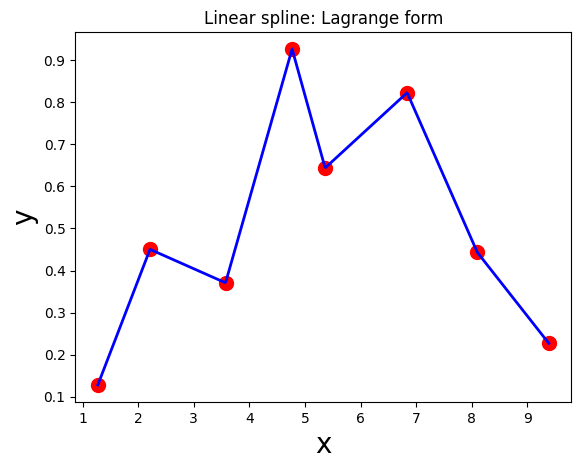

  max error at data points: 2.42e-03
linear_spline_standard


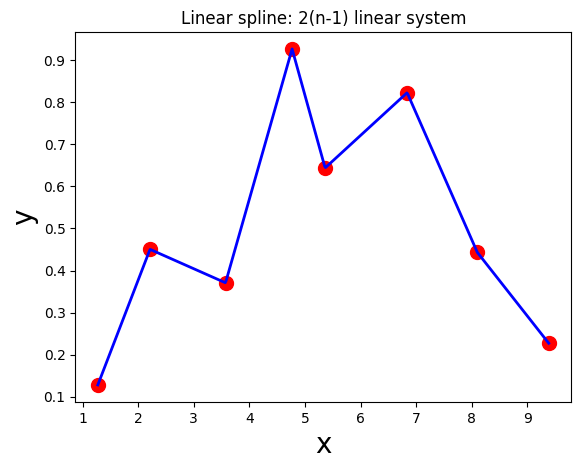

quad_spline_sequential


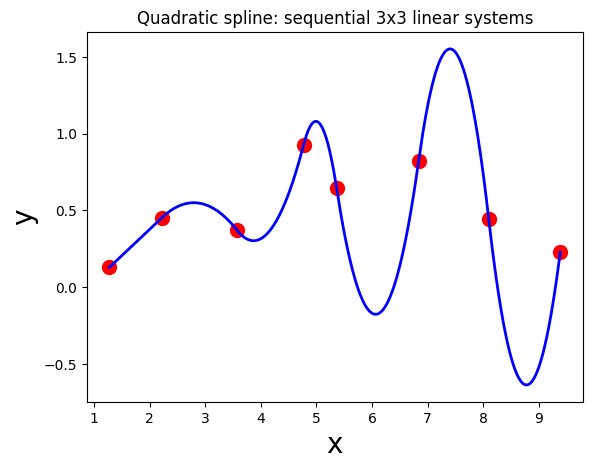

quad_spline_standard


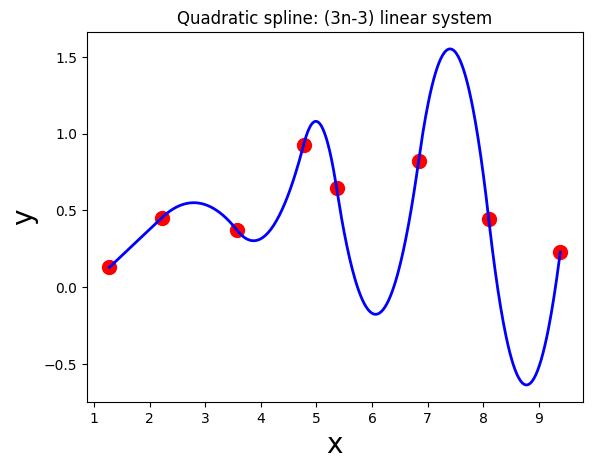

quad_spline_lagrange


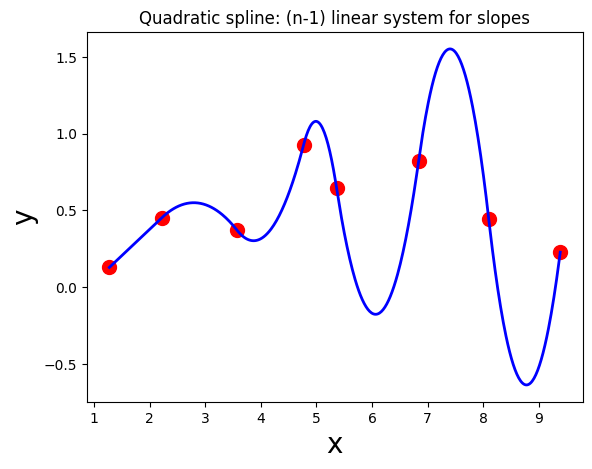

cubic_spline_lagrange


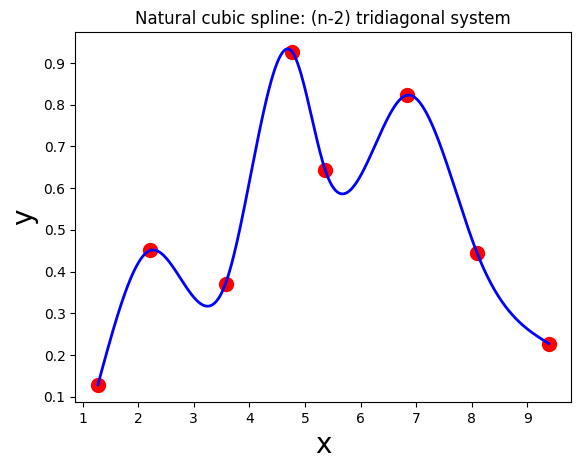

cubic_spline_standard


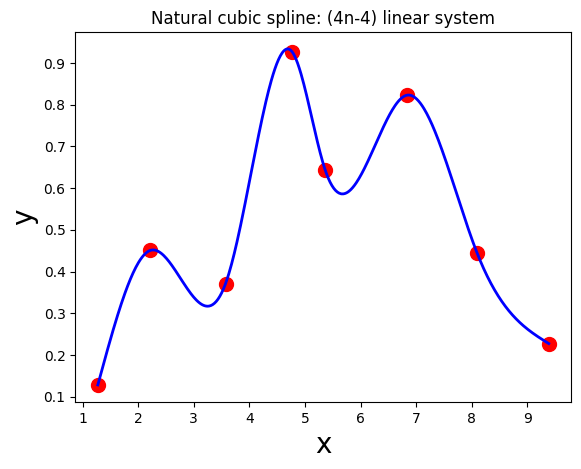


모든 메서드 정상 실행 완료


In [ ]:
# === 실행 및 검증 ===
if __name__ == "__main__":
    solver = SplineInterpolation.random_points(n=8, seed=42)

    print("linear_spline_lagrange")
    xx, yy = solver.linear_spline_lagrange()

    print(f"  max error at data points: {np.max(np.abs(np.interp(solver.x, xx, yy) - solver.y)):.2e}")

    print("linear_spline_standard")
    solver.linear_spline_standard()

    print("quad_spline_sequential")
    solver.quad_spline_sequential()

    print("quad_spline_standard")
    solver.quad_spline_standard()

    print("quad_spline_lagrange")
    solver.quad_spline_lagrange()

    print("cubic_spline_lagrange")
    solver.cubic_spline_lagrange()

    print("cubic_spline_standard")
    solver.cubic_spline_standard()

    print("\n모든 메서드 정상 실행 완료")

---

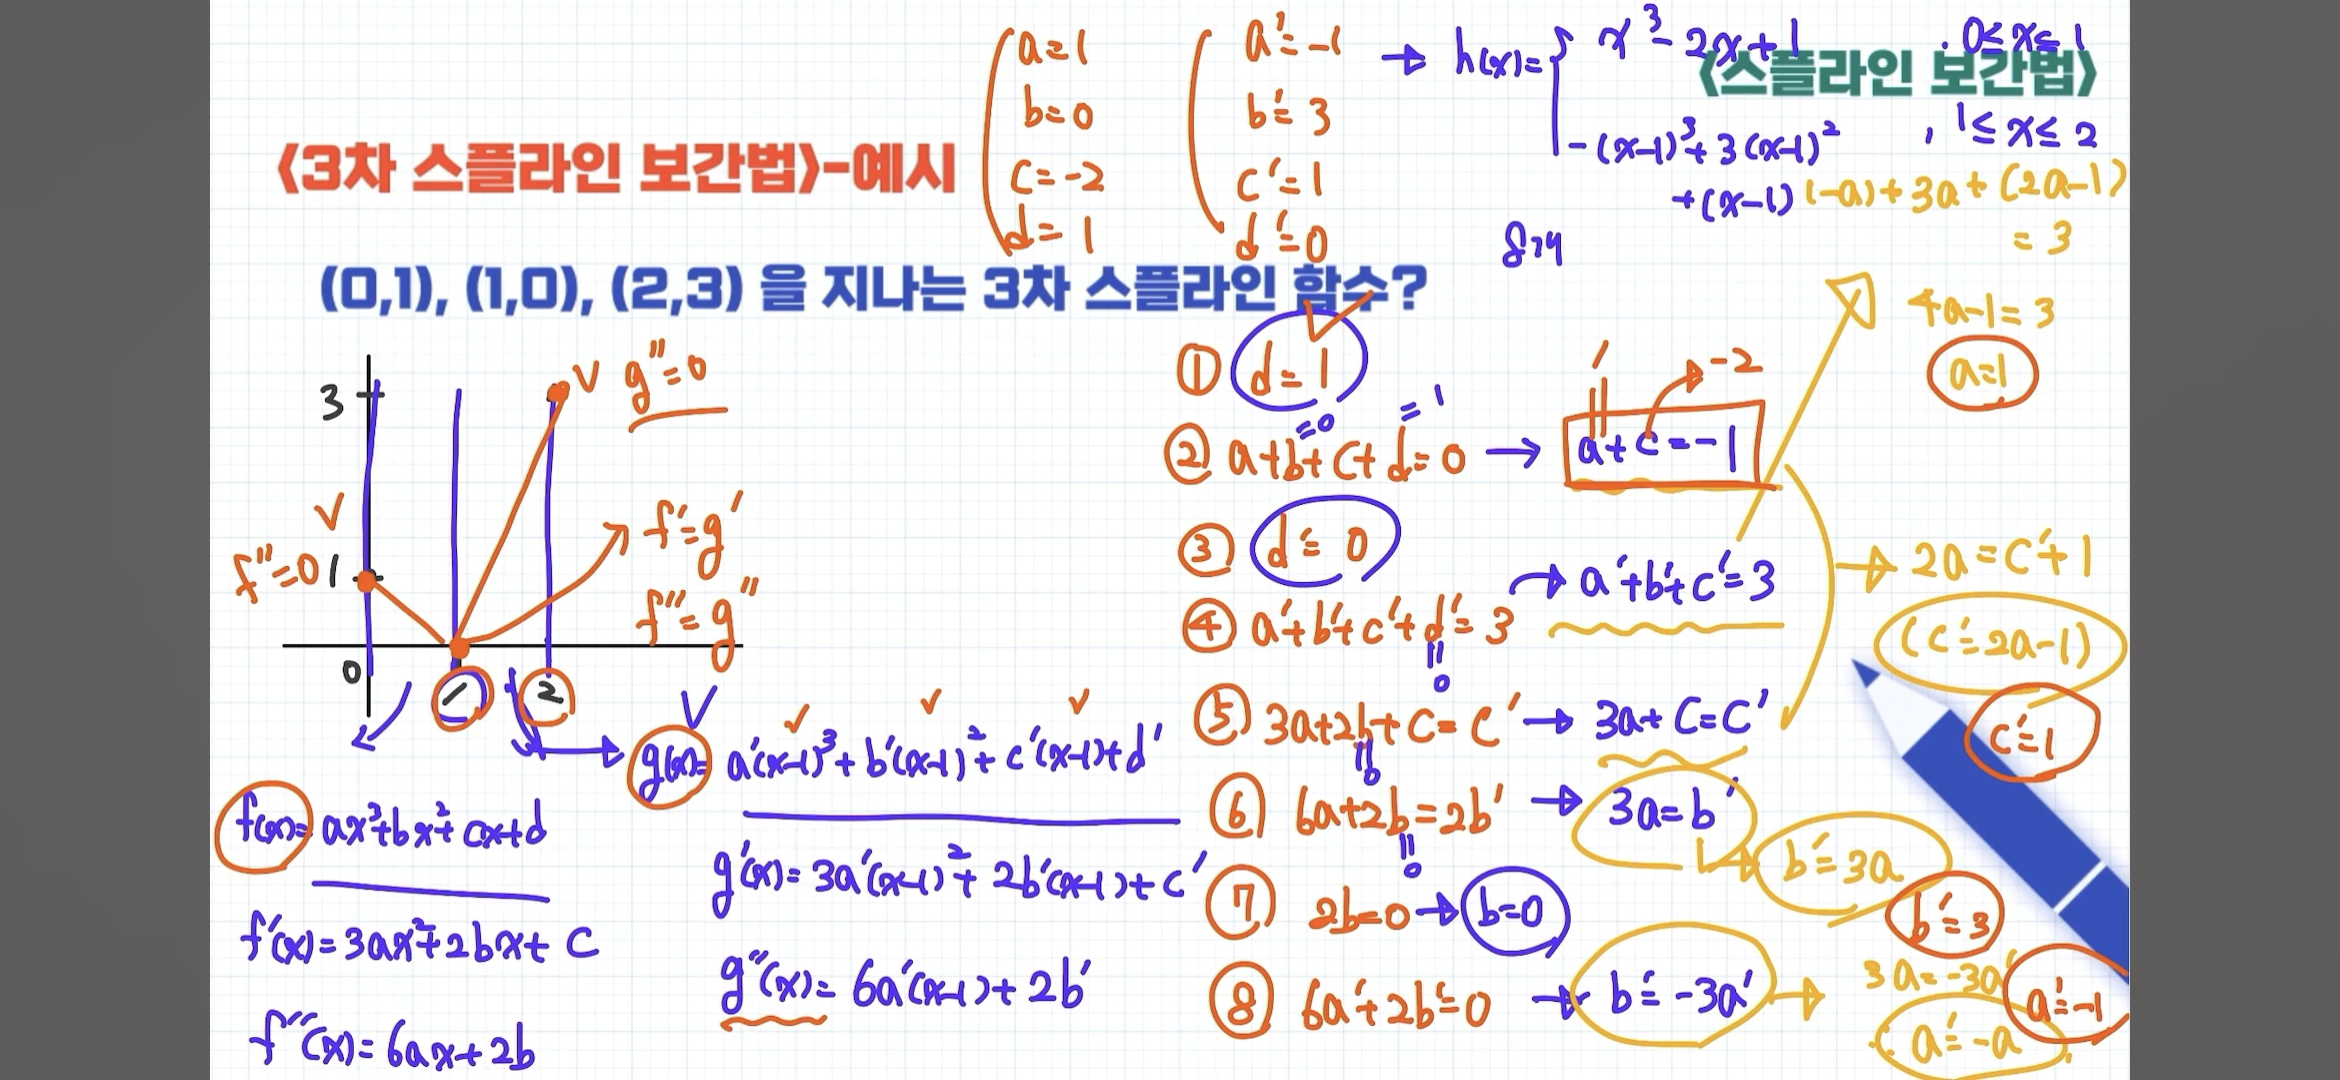

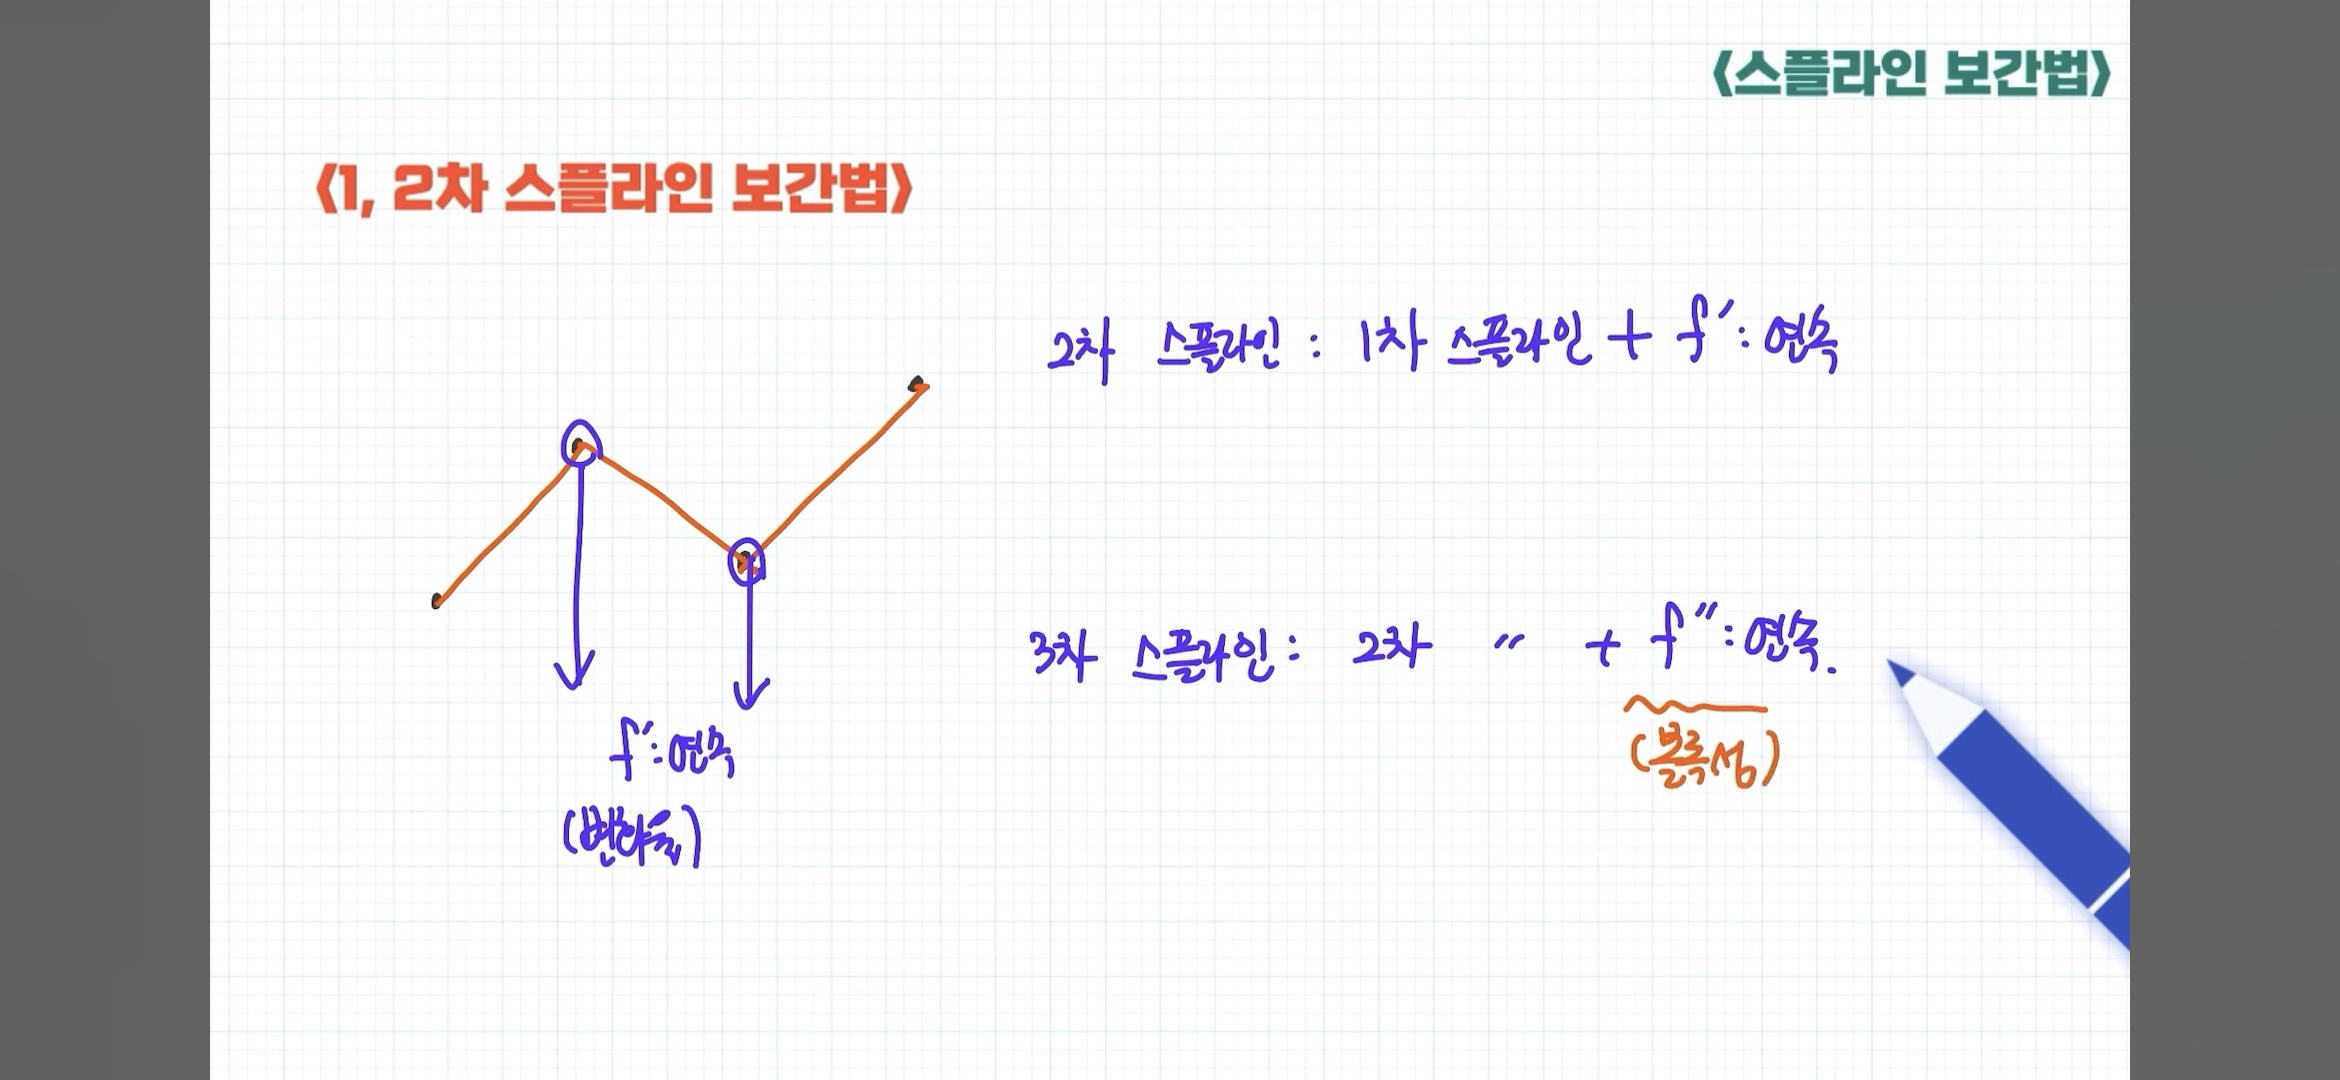 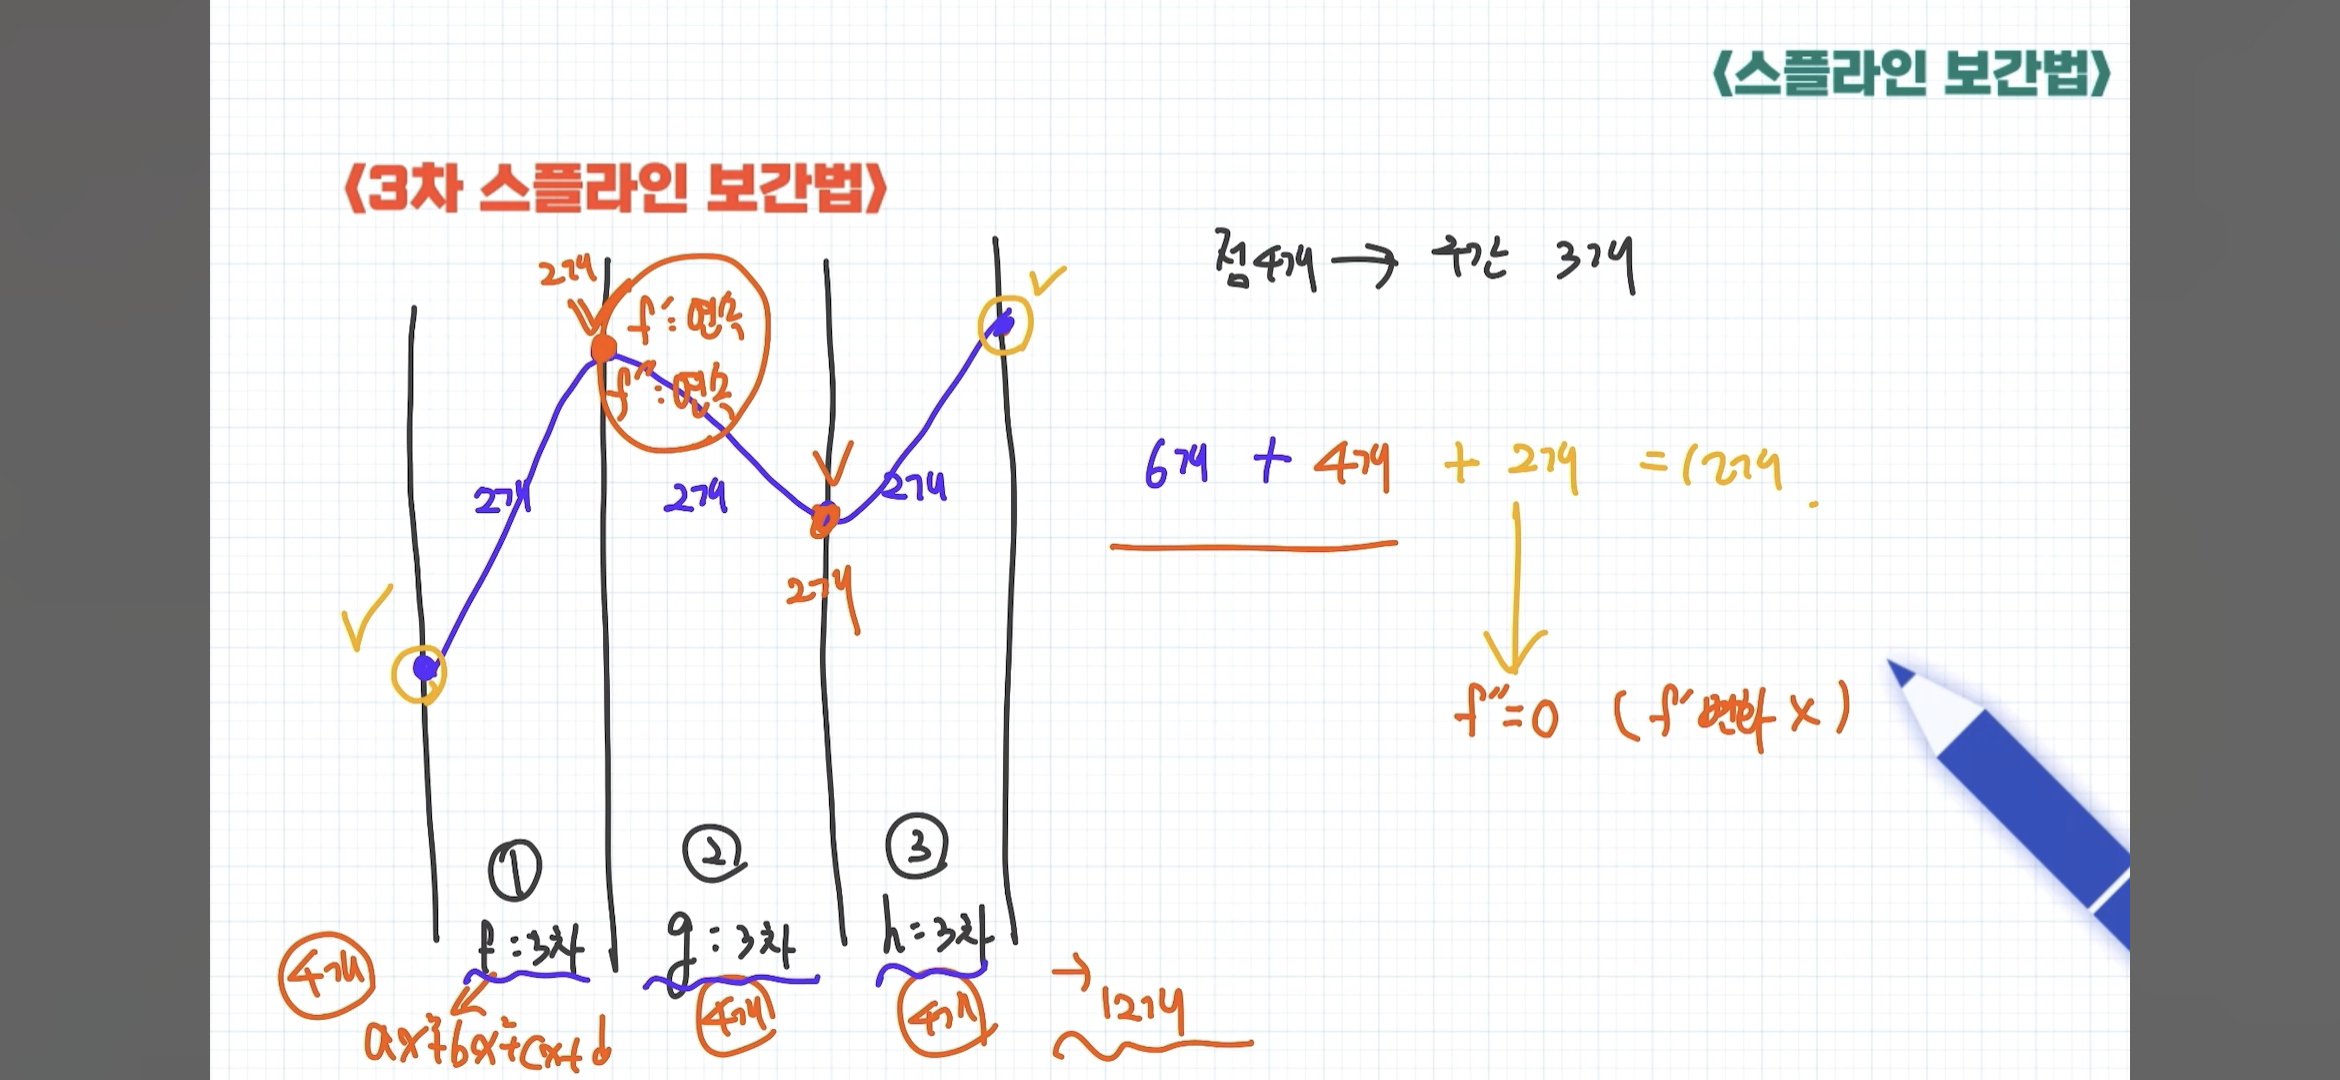

---

In [ ]:
""" 
[MATLAB]

clear all;
clc;

n = 5
x = 1:10
# y = rand(1, length(x))
y = rand(1, n)

plot(x, y, "ro")
p = polyfit(x, y, 1) # cubic() / interp1() ...
xx = 1:0.1:n
yy = polyval(p, xx)

hold on;
plot(xx, yy, "b-")
"""